# ANN: a shallow artificial neural network

An ANN is a network of connected layers of "neurons". This one is deliberately **shallow**: a single hidden layer. It is the simplest neural network that can learn non-linear patterns, and it serves as the baseline for the deeper models (DNN, CNN, RNN), so you can show whether extra depth actually helps.

**Feasibility:** fully feasible, fast to train, and fast enough to run live. Run after the preprocessing notebook. Everything is evaluated on the validation set.

## 1. Imports

In [3]:
# %pip install tensorflow matplotlib     # uncomment once if missing

import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
import keras
from keras import layers

print("keras", keras.__version__)

keras 3.15.1


## 2. Config

In [4]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

LEARNING_RATE = 1e-3
BATCH_SIZE = 512
EPOCHS = 60              # early stopping usually ends training much sooner
PATIENCE = 8

HIDDEN_UNITS = 64       # one hidden layer
DROPOUT = 0.2

## 3. Load the processed data

In [5]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype(int), data["y_bin_val"].astype(int)
ym_train, ym_val = data["y_multi_train"].astype(int), data["y_multi_val"].astype(int)
feature_names = meta["feature_names"]
class_names = meta["class_names"]
n_features, n_classes = X_train.shape[1], len(class_names)

cw_bin = {int(k): v for k, v in meta["class_weight_binary"].items()}
cw_multi = {int(k): v for k, v in meta["class_weight_multi"].items()}

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
print("classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)
classes: ['Normal', 'DoS', 'Reconnaissance', 'Fuzzers', 'Exploits', 'Generic', 'Other']


## 4. Helpers (same evaluation as every other notebook)

In [6]:
def ms_per_1000(predict_fn, X, n=5000):
    """Prediction time in milliseconds per 1,000 flows (a model that is too slow cannot run live)."""
    Xs = X[:n]
    t0 = time.perf_counter()
    predict_fn(Xs)
    return round(1e6 * (time.perf_counter() - t0) / len(Xs), 1)


def report_binary(y_true, pred, title, score=None, ms=None):
    print(classification_report(y_true, pred, target_names=["Normal", "Attack"], digits=4))
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    fpr = fp / max(fp + tn, 1)
    if score is not None:
        print(f"ROC-AUC:              {roc_auc_score(y_true, score):.4f}")
    print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
    print(f"False negative rate:  {fn / max(fn + tp, 1):.4f}  ({fn} attacks missed)")
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
    ax.set_title(f"{title}: validation confusion matrix")
    plt.tight_layout()
    plt.show()
    return {"model": title,
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "false_pos_rate": fpr,
            "ms_per_1000_flows": ms}


def report_multiclass(y_true, pred, title, ms=None):
    labels = list(range(n_classes))
    print(classification_report(y_true, pred, labels=labels, target_names=class_names,
                                digits=4, zero_division=0))
    print("macro F1:    %.4f" % f1_score(y_true, pred, average="macro"))
    print("weighted F1: %.4f" % f1_score(y_true, pred, average="weighted"))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
    axes[0].set_title("Counts")
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
    axes[1].set_title("Row-normalised (share of each true class)")
    plt.suptitle(f"{title}: validation confusion matrices")
    plt.tight_layout()
    plt.show()
    flagged = np.asarray(pred) != 0          # class 0 is Normal
    rows = []
    for i, name in enumerate(class_names):
        m = np.asarray(y_true) == i
        rows.append({"true class": name, "flows": int(m.sum()),
                     "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                     "correct type (%)": round(100 * (np.asarray(pred)[m] == i).mean(), 2)})
    display(pd.DataFrame(rows))
    return {"model": title + " (macro)",
            "precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "f1": f1_score(y_true, pred, average="macro"),
            "false_pos_rate": np.nan,
            "ms_per_1000_flows": ms}

In [7]:
keras.utils.set_random_seed(SEED)


def head(x, n_out, binary):
    if binary:
        return layers.Dense(1, activation="sigmoid")(x)
    return layers.Dense(n_out, activation="softmax")(x)


def compile_model(model, binary):
    if binary:
        loss, metrics = "binary_crossentropy", [keras.metrics.AUC(name="auc")]
    else:
        loss, metrics = "sparse_categorical_crossentropy", ["accuracy"]
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=loss, metrics=metrics)
    return model


def fit_model(model, X_tr, y_tr, X_va, y_va, class_weight):
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    ]
    t0 = time.time()
    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS,
                     batch_size=BATCH_SIZE, class_weight=class_weight,
                     callbacks=callbacks, verbose=2)
    print(f"trained {len(hist.history['loss'])} epochs in {time.time() - t0:.1f}s")
    return hist


def plot_history(hist, metric, title):
    h = hist.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="train")
    axes[0].plot(h["val_loss"], label="validation")
    axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(h[metric], label="train")
    axes[1].plot(h["val_" + metric], label="validation")
    axes[1].set_title(metric.upper()); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

## 5. Architecture

Input (45 features), then one Dense layer with ReLU, dropout, and an output layer (1 sigmoid unit for binary, one softmax unit per class for multiclass).

In [8]:
def build_model(n_in, n_out, binary):
    inputs = keras.Input(shape=(n_in,))
    x = layers.Dense(HIDDEN_UNITS, activation="relu")(inputs)
    x = layers.Dropout(DROPOUT)(x)
    return keras.Model(inputs, head(x, n_out, binary))

## 6. Binary model (normal vs attack)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 39)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,625 (10.25 KB)

 Trainable params: 2,625 (10.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
274/274 - 1s - 5ms/step - auc: 0.9133 - loss: 0.3723 - val_auc: 0.9666 - val_loss: 0.2544 - learning_rate: 0.0010
Epoch 2/60
274/274 - 1s - 2ms/step - auc: 0.9585 - loss: 0.2580 - val_auc: 0.9761 - val_loss: 0.2129 - learning_rate: 0.0010
Epoch 3/60
274/274 - 1s - 2ms/step - auc: 0.9672 - loss: 0.2295 - val_auc: 0.9793 - val_loss: 0.1968 - learning_rate: 0.0010
Epoch 4/60
274/274 - 1s - 2ms/step - auc: 0.9713 - loss: 0.2146 - val_auc: 0.9814 - val_loss: 0.1837 - learning_rate: 0.0010
Epoch 5/60
274/274 - 1s - 2ms/step - auc: 0.9739 - loss: 0.2046 - val_auc: 0.9826 - val_loss: 0.1776 - learning_rate: 0.0010
Epoch 6/60
274/274 - 1s - 2ms/step - auc: 0.9758 - loss: 0.1970 - val_auc: 0.9839 - val_loss: 0.1692 - learning_rate: 0.0010
Epoch 7/60
274/274 - 0s - 2ms/step - auc: 0.9773 - loss: 0.1906 - val_auc: 0.9847 - val_loss: 0.1647 - learning_rate: 0.0010
Epoch 8/60
274/274 - 1s - 2ms/step - auc: 0.9786 - loss: 0.1856 - val_auc: 0.9855 - val_loss: 0.1614 - learning_rate: 0.0010


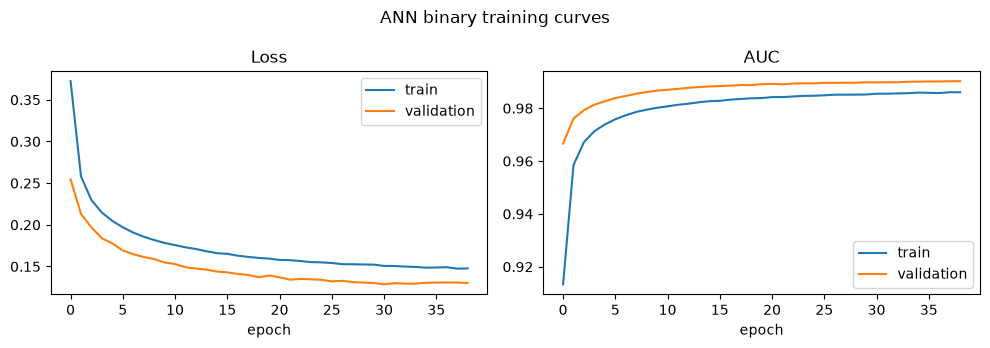

In [9]:
model_bin = compile_model(build_model(n_features, 1, True), True)
model_bin.summary()
hist_bin = fit_model(model_bin, X_train, yb_train, X_val, yb_val, cw_bin)
plot_history(hist_bin, "auc", "ANN binary training curves")

              precision    recall  f1-score   support

      Normal     0.8625    0.9521    0.9051     11200
      Attack     0.9763    0.9288    0.9520     23869

    accuracy                         0.9362     35069
   macro avg     0.9194    0.9404    0.9285     35069
weighted avg     0.9400    0.9362    0.9370     35069

ROC-AUC:              0.9900
False positive rate:  0.0479  (537 normal flows flagged as attacks)
False negative rate:  0.0712  (1700 attacks missed)


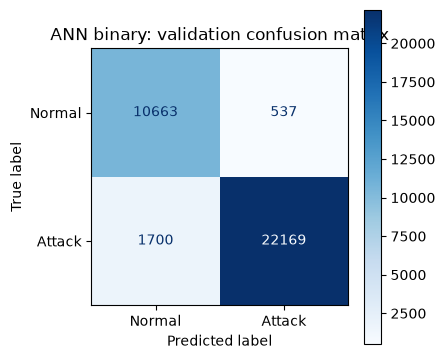

In [10]:
proba_bin = model_bin.predict(X_val, batch_size=4096, verbose=0).ravel()
pred_bin = (proba_bin >= 0.5).astype(int)
row_bin = report_binary(
    yb_val, pred_bin, "ANN binary", score=proba_bin,
    ms=ms_per_1000(lambda X: model_bin.predict(X, batch_size=4096, verbose=0), X_val))

## 7. Multiclass model

Epoch 1/60
274/274 - 1s - 4ms/step - accuracy: 0.6057 - loss: 1.2706 - val_accuracy: 0.7132 - val_loss: 0.8356 - learning_rate: 0.0010
Epoch 2/60
274/274 - 1s - 2ms/step - accuracy: 0.6816 - loss: 1.0254 - val_accuracy: 0.7220 - val_loss: 0.7312 - learning_rate: 0.0010
Epoch 3/60
274/274 - 1s - 2ms/step - accuracy: 0.6945 - loss: 0.9696 - val_accuracy: 0.7313 - val_loss: 0.6954 - learning_rate: 0.0010
Epoch 4/60
274/274 - 1s - 2ms/step - accuracy: 0.7040 - loss: 0.9339 - val_accuracy: 0.7376 - val_loss: 0.6758 - learning_rate: 0.0010
Epoch 5/60
274/274 - 1s - 2ms/step - accuracy: 0.7115 - loss: 0.9091 - val_accuracy: 0.7429 - val_loss: 0.6596 - learning_rate: 0.0010
Epoch 6/60
274/274 - 1s - 2ms/step - accuracy: 0.7177 - loss: 0.8923 - val_accuracy: 0.7478 - val_loss: 0.6442 - learning_rate: 0.0010
Epoch 7/60
274/274 - 1s - 2ms/step - accuracy: 0.7224 - loss: 0.8764 - val_accuracy: 0.7517 - val_loss: 0.6366 - learning_rate: 0.0010
Epoch 8/60
274/274 - 1s - 2ms/step - accuracy: 0.7259 -

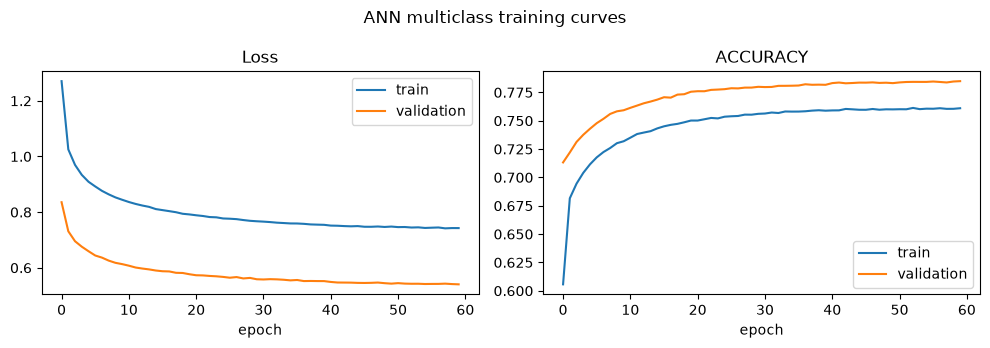

In [11]:
model_multi = compile_model(build_model(n_features, n_classes, False), False)
hist_multi = fit_model(model_multi, X_train, ym_train, X_val, ym_val, cw_multi)
plot_history(hist_multi, "accuracy", "ANN multiclass training curves")

                precision    recall  f1-score   support

        Normal     0.9910    0.8434    0.9112     11200
           DoS     0.3306    0.8015    0.4682      2453
Reconnaissance     0.7666    0.8090    0.7872      2099
       Fuzzers     0.6254    0.8535    0.7219      3637
      Exploits     0.8352    0.4720    0.6031      6678
       Generic     0.9978    0.9801    0.9889      8000
         Other     0.4085    0.3184    0.3578      1002

      accuracy                         0.7849     35069
     macro avg     0.7079    0.7254    0.6912     35069
  weighted avg     0.8487    0.7849    0.7964     35069

macro F1:    0.6912
weighted F1: 0.7964


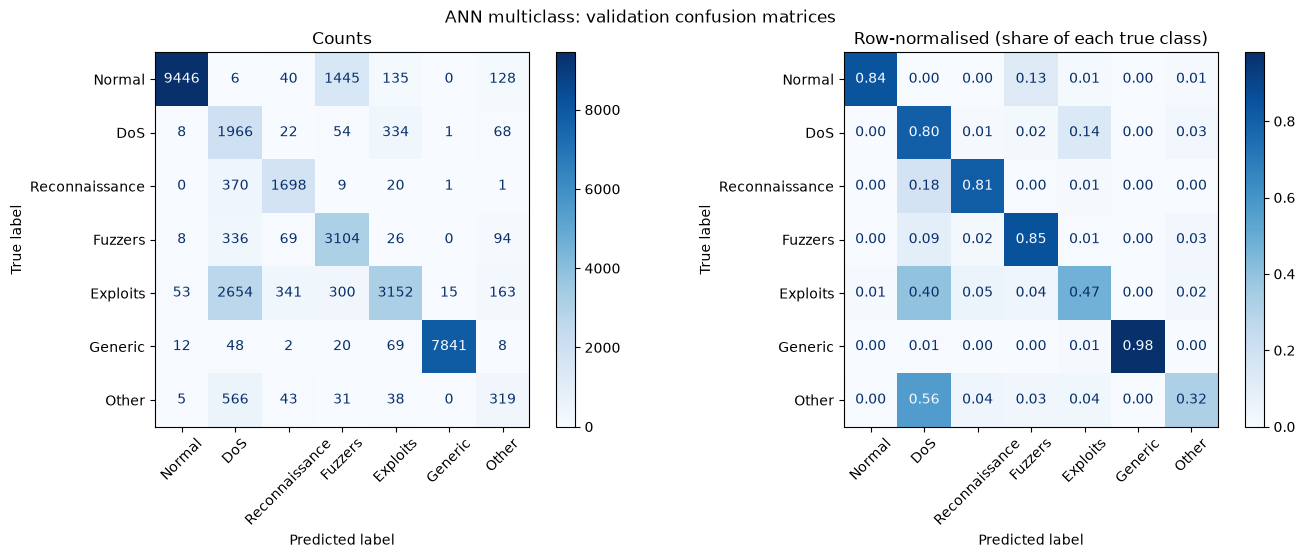

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,15.66,84.34
1,DoS,2453,99.67,80.15
2,Reconnaissance,2099,100.00,80.90
3,Fuzzers,3637,99.78,85.35
4,Exploits,6678,99.21,47.20
5,Generic,8000,99.85,98.01
6,Other,1002,99.50,31.84


In [12]:
pred_multi = model_multi.predict(X_val, batch_size=4096, verbose=0).argmax(axis=1)
row_multi = report_multiclass(
    ym_val, pred_multi, "ANN multiclass",
    ms=ms_per_1000(lambda X: model_multi.predict(X, batch_size=4096, verbose=0), X_val))

## 8. Save the models and compare with the other notebooks

The ANN is small and fast, so it is a realistic live model. Load it with `keras.models.load_model` the same way as the MLP.

In [13]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)

model_bin.save(mdir / "ann_binary.keras")
model_multi.save(mdir / "ann_multiclass.keras")
pd.DataFrame([row_bin, row_multi]).to_csv(mdir / "ann_validation_summary.csv", index=False)
for f in sorted(mdir.glob("ann_*")):
    print(f"{f.name:32s} {f.stat().st_size / 1e3:9.1f} KB")

ann_binary.keras                      57.4 KB
ann_multiclass.keras                  61.8 KB
ann_validation_summary.csv             0.2 KB


In [14]:
# compare with every other model whose notebook has been run
frames = [pd.read_csv(f) for f in sorted(Path(MODEL_DIR).glob("*_validation_summary.csv"))]
pd.concat(frames, ignore_index=True).round(4)

,model,precision,recall,f1,false_pos_rate,ms_per_1000_flows
0,Autoencoder binary,0.9666,0.6791,0.7977,0.0500,NaN
1,ANN binary,0.9763,0.9288,0.9520,0.0479,10.0
2,ANN multiclass (macro),0.7079,0.7254,0.6912,NaN,10.0
3,MLP binary,0.9800,0.9279,0.9532,0.0404,NaN
4,MLP multiclass (macro),0.7120,0.7350,0.6985,NaN,NaN
5,RF binary,0.9757,0.9610,0.9683,0.0511,NaN
6,RF multiclass (macro),0.6378,0.6286,0.6239,NaN,NaN
7,XGBoost binary,0.9823,0.9537,0.9678,0.0367,NaN
8,XGBoost multiclass (macro),0.6849,0.7060,0.6761,NaN,NaN
